# M3 · Statistical evaluation and pooling comparison
All numbers below are read from **actual saved posterior fits** and the source-derived M2B panel. Only evaluation opens `ground_truth.json`. Holdout results condition on the pre-outcome marketing plan and market context; they are not unconditional future forecasts. The promotional decomposition is model-based and assumption-dependent, not experiment-validated causal lift.

In [1]:
import json
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from mmm_lab.evaluate import evaluate_models, posterior_components
from mmm_lab.model import load_model_data
from mmm_lab.paths import ARTIFACTS_DIR

evaluation_path = ARTIFACTS_DIR / 'evaluation.json'
if not evaluation_path.exists():
    evaluate_models()
results = json.loads(evaluation_path.read_text())
data = load_model_data()
assert results['model_input_sha256'] == data.input_sha256
models = results['models']

## Convergence and held-out accuracy
R-hat near or below 1.01, adequate bulk effective sample size and zero unresolved divergences are desired, but none alone proves model validity. WAPE is total absolute error divided by observed units; bias is predicted minus observed units. The 90% holdout interval includes Normal observation noise and is a **predictive** interval.

,divergences,max_rhat,min_bulk_ess,parameters_with_rhat_above_1_01,train_bias_units_predicted_minus_observed,train_mae_units,train_predictive_90_coverage,train_wape,holdout_bias_units_predicted_minus_observed,holdout_mae_units,holdout_predictive_90_coverage,holdout_wape
pooling,,,,,,,,,,,,
complete,0,1.0056,266.3,[],-0.124,36.932,0.9283,0.04510,-9.077,36.984,0.925,0.04044
none,0,1.0097,427.7,[],0.103,36.819,0.9300,0.04496,-9.150,37.114,0.925,0.04058
partial,0,1.0043,1146.4,[],-0.053,36.876,0.9283,0.04503,-9.023,36.954,0.925,0.04040


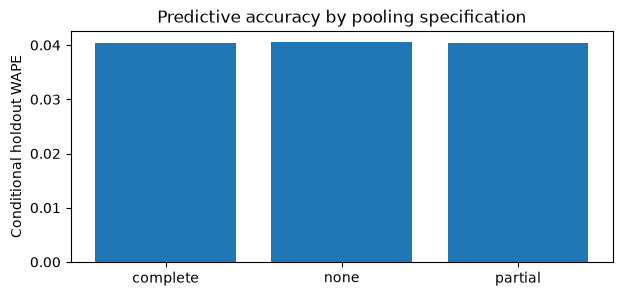

In [2]:
rows = []
for name, model in models.items():
    rows.append({'pooling': name, **model['diagnostics'], **{f'train_{k}': v for k, v in model['train'].items() if not isinstance(v, dict)}, **{f'holdout_{k}': v for k, v in model['conditional_holdout'].items() if not isinstance(v, dict)}})
display(pd.DataFrame(rows).set_index('pooling'))
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar([r['pooling'] for r in rows], [r['holdout_wape'] for r in rows])
ax.set(ylabel='Conditional holdout WAPE', title='Predictive accuracy by pooling specification')
plt.show()

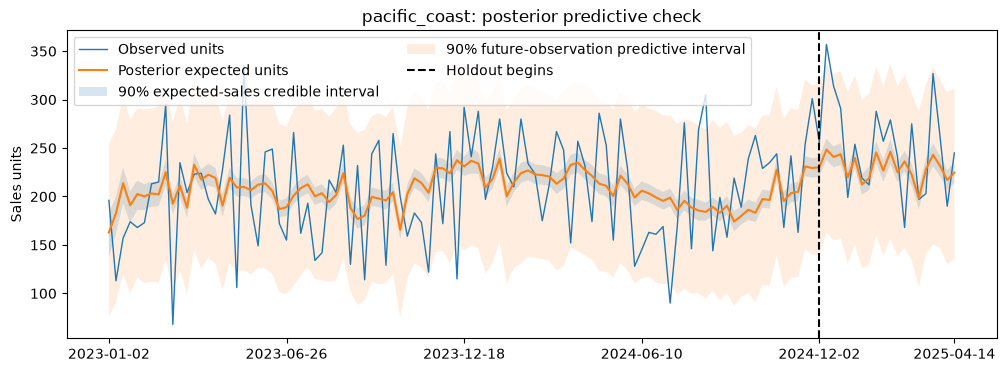

In [3]:
manifest = json.loads((ARTIFACTS_DIR / 'fit_manifest.json').read_text())
partial = az.from_netcdf(ARTIFACTS_DIR / manifest['files']['partial']['path'])
baseline, channel, expected, noise = posterior_components(data, partial['posterior'])
segment = 'pacific_coast'
s = data.segments.index(segment)
mean = expected[:, s, :].mean(axis=0)
credible_low, credible_high = np.quantile(expected[:, s, :], [0.05, 0.95], axis=0)
rng = np.random.default_rng(47)
predictive = expected[:, s, :] + rng.normal(size=expected[:, s, :].shape) * noise[:, s, None]
predictive_low, predictive_high = np.quantile(predictive, [0.05, 0.95], axis=0)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(data.weeks, data.sales[s], label='Observed units', linewidth=1)
ax.plot(data.weeks, mean, label='Posterior expected units')
ax.fill_between(data.weeks, credible_low, credible_high, alpha=.18, label='90% expected-sales credible interval')
ax.fill_between(data.weeks, predictive_low, predictive_high, alpha=.13, label='90% future-observation predictive interval')
ax.axvline(data.weeks[100], color='black', linestyle='--', label='Holdout begins')
ax.set(title=f'{segment}: posterior predictive check', ylabel='Sales units')
ax.set_xticks([data.weeks[i] for i in (0, 25, 50, 75, 100, 119)])
ax.legend(ncol=2)
plt.show()

## Synthetic truth recovery and shrinkage
The coefficient comparison uses the generator's **maximum** channel effect, not the effect at observed spend. Its 90% intervals are parameter credible intervals. Contribution coverage compares each modeled segment-week/channel contribution with hidden synthetic truth. Recovery can fail even when held-out sales prediction is good because overlapping channels and baseline terms are confounded.

In [4]:
display(pd.DataFrame([{'pooling': name, **{k:v for k,v in m['recovery'].items() if k not in ('coefficient_by_segment_channel','shared_shape_recovery')}} for name,m in models.items()]).set_index('pooling'))
display(pd.DataFrame(models['partial']['recovery']['shared_shape_recovery']))
comparison = pd.concat([pd.DataFrame(m['recovery']['coefficient_by_segment_channel']).assign(pooling=name) for name,m in models.items()])
display(comparison.query("segment_id in ['mountain_west','pacific_coast']").sort_values(['segment_id','channel','pooling']))
width = comparison.assign(interval_width=lambda d: d.credible_90_high-d.credible_90_low).pivot_table(index=['segment_id','channel'], columns='pooling', values='interval_width')
display(width)

,baseline_90_coverage,baseline_mae_units,channel_contribution_90_coverage,channel_contribution_mae_units,coefficient_90_coverage,coefficient_mean_absolute_error_units
pooling,,,,,,
complete,0.5653,30.170,0.9301,11.949,0.6667,52.376
none,0.9236,32.648,0.9986,11.255,0.9444,37.972
partial,0.7972,30.920,0.9968,11.596,0.8333,49.981


,channel,contains_truth,credible_90_high,credible_90_low,parameter,posterior_mean,true_value,units
0,coupon,True,0.9491,0.1036,adstock_alpha,0.6174,0.25,unitless
1,coupon,True,7571.9875,1485.6024,half_saturation,3749.4418,2800.00,USD
2,retailer_promotion,True,0.5501,0.0513,adstock_alpha,0.2509,0.45,unitless
3,retailer_promotion,True,6943.1270,1660.8387,half_saturation,3675.8620,3300.00,USD
4,digital,True,0.8380,0.0762,adstock_alpha,0.3955,0.65,unitless
5,digital,True,7081.4311,1584.1090,half_saturation,3733.4651,3500.00,USD


,channel,credible_90_high,credible_90_low,posterior_mean_max_units,segment_id,true_max_units,pooling
12,coupon,122.437,30.570,72.267,mountain_west,80.0,complete
12,coupon,263.676,40.473,134.406,mountain_west,80.0,none
12,coupon,172.915,24.339,82.271,mountain_west,80.0,partial
14,digital,221.867,53.974,130.530,mountain_west,65.0,complete
14,digital,305.626,34.270,132.935,mountain_west,65.0,none
14,digital,257.822,45.801,136.164,mountain_west,65.0,partial
13,retailer_promotion,241.162,84.272,159.776,mountain_west,70.0,complete
13,retailer_promotion,241.139,33.393,112.385,mountain_west,70.0,none
13,retailer_promotion,269.342,66.616,156.177,mountain_west,70.0,partial
15,coupon,122.437,30.570,72.267,pacific_coast,65.0,complete


pooling                           complete     none  partial
segment_id    channel                                       
great_lakes   coupon                91.867  149.506  110.103
              digital              167.893  158.480  174.878
              retailer_promotion   156.890  173.615  172.870
mountain_west coupon                91.867  223.203  148.576
              digital              167.893  271.356  212.021
              retailer_promotion   156.890  207.746  202.726
northeast     coupon                91.867  165.531  136.583
              digital              167.893  179.480  188.019
              retailer_promotion   156.890  208.542  184.917
pacific_coast coupon                91.867  159.712  110.453
              digital              167.893  194.467  189.480
              retailer_promotion   156.890  211.281  202.650
south_central coupon                91.867  144.095  117.083
              digital              167.893  318.028  252.035
              retailer_promotion   156.890  198.710  192.107
southeast     coupon                91.867  111.169  101.041
              digital              167.893  192.498  186.409
              retailer_promotion   156.890  196.412  170.868

## Correlated campaigns and limitations
The table below is computed on training planned spend. High pairwise correlations make individual channel response harder to identify; compare recovery and interval widths before favoring any pooling strategy. Partial pooling can reduce variance for weak-information regions and can bias heterogeneous true effects toward the population. Prior predictive checks in notebook 02 expose whether the declared priors generate plausible sales scales.

In [5]:
display(pd.DataFrame(results['training_campaign_spend_correlations']).T)
display(pd.DataFrame([models['partial']['prior_sensitivity']]))
for limitation in results['limitations']:
    print('•', limitation)

,coupon_vs_digital,coupon_vs_retailer_promotion,retailer_promotion_vs_digital
great_lakes,0.6151,0.5950,0.5374
mountain_west,0.3958,0.5030,0.5811
northeast,0.5004,0.5201,0.5570
pacific_coast,0.4919,0.6058,0.5191
south_central,0.6331,0.5744,0.6420
southeast,0.6082,0.5641,0.5260


,alternate_log_population_prior_sigma,available_draws,base_log_population_prior_sigma,importance_effective_draws,max_absolute_coefficient_mean_shift_units,mean_absolute_coefficient_mean_shift_units,method
0,1.0,3200,0.7,2172.9,9.696,6.59,"posterior importance reweighting, not independ..."


• Synthetic generator truth is available for evaluation only, never model fitting.
• Three channels overlap and co-vary; individual effects and shapes may be weakly identified.
• Holdout predictions condition on planned spend and pre-outcome market context.
• Normal observation noise approximates rounded nonnegative integer sales units.
• Model-based contributions are assumption dependent, not experiment-validated incrementality.
• Prior sensitivity reweights one population prior only; poor importance ESS would require an independent refit.
